# Enhanced-MCAD: Deep Learning Intrusion Detection for SDN

**Destiny Jerez · Rashmi Raveendran · Montclair State University**

This notebook detects attacks in Software-Defined Network (SDN) traffic from the [MCAD-SDN dataset](https://www.kaggle.com/datasets/lailahalman/mcad-sdn/data). It classifies each flow record as **Normal, Reconnaissance, Phishing (credential attacks) or Malware (DDoS)**, and compares a classical baseline with three deep learning models (MLP, Transformer, GraphSAGE GNN) plus an ensemble.

**The key finding is about evaluation.** Each capture file is a time series of *cumulative* switch counters. With a random train/test split, near-identical neighbouring rows land on both sides, and every model scores close to 100%. That reflects leakage, not real detection skill. This notebook uses a **chronological split** (train on the first 80% of each capture, test on the last 20%) and turns the cumulative counters into **per-interval rates**. That gives realistic, defensible numbers.

Run top to bottom on a CPU in about 10 minutes; a GPU is not required.

## 1. Setup

In [1]:
# Colab already has PyTorch; this installs PyTorch Geometric for the GNN.
%pip install -q torch_geometric

In [2]:
import os, glob, zipfile, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs("images", exist_ok=True)
CLASSES = ["NORMAL", "RECON", "PHISHING", "MALWARE"]

## 2. Load the data

Download the dataset from Kaggle and upload the zip to this notebook's folder (in Colab, use the file panel on the left). The cell below unzips it if needed. Each CSV is one capture of one traffic type; `features.txt` lists the 27 column names.

In [3]:
DATA_DIR = os.environ.get("MCAD_DATA_DIR", "mcad_sdn")
if not os.path.isdir(DATA_DIR):
    zips = glob.glob("*.zip")
    assert zips, "Upload the MCAD-SDN zip from Kaggle first."
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall(DATA_DIR)

COLUMNS = ["src", "dst", "table_id", "ip_bytes", "ip_packet", "ip_duration", "in_port", "dl_dst",
           "port_bytes", "port_packet", "port_flow_count", "table_active_count", "table_lookup_count",
           "table_matched_count", "port_rx_packets", "port_tx_packets", "port_rx_bytes", "port_tx_bytes",
           "port_rx_dropped", "port_tx_dropped", "port_rx_errors", "port_tx_errors", "port_rx_frame_err",
           "port_rx_over_err", "port_rx_crc_err", "port_collisions", "port_duration_sec"]

def map_label(filename):
    # Group the 14 capture files into 4 classes
    if filename.startswith("normal"):
        return "NORMAL"
    if filename in ("attack_os_port_scan.csv", "attack_sql_injection.csv"):
        return "RECON"
    if filename in ("attack_ddos_tcp.csv", "attack_ddos_udp.csv", "ddos_attack_scapy_new.csv"):
        return "MALWARE"
    return "PHISHING"   # brute force, VNC, Samba, command injection

frames = []
for path in sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)):
    name = os.path.basename(path)
    part = pd.read_csv(path, header=None, names=COLUMNS)
    part["file"] = name
    part["label"] = map_label(name)
    part["position"] = np.arange(len(part)) / len(part)   # 0 = start of capture, 1 = end
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
missing = df[COLUMNS].isna().any(axis=1)
print(f"Dropping {missing.sum()} rows with missing values")
df = df[~missing].reset_index(drop=True)
df["y"] = df["label"].map({c: i for i, c in enumerate(CLASSES)})
print(f"{len(df):,} flow records from {df['file'].nunique()} capture files")
df["label"].value_counts()

Dropping 4 rows with missing values


600,639 flow records from 14 capture files


label
MALWARE     174860
PHISHING    171952
NORMAL      140368
RECON       113459
Name: count, dtype: int64

## 3. Spotting the leakage

Two things make this dataset easy to "solve" by accident:

1. **Identifiers.** The `src`/`dst` IPs and the `dl_dst` MAC address almost name the capture file (attack captures come from `192.168.221.129`, normal ones from `10.0.0.x`).
2. **Cumulative counters.** Columns like `port_rx_bytes` only ever increase during a capture, so neighbouring rows are near-duplicates. A random split puts row *t* in training and row *t+1* in testing.

In [4]:
df.groupby("file")["src"].agg(lambda s: s.value_counts().index[0]).to_frame("most common src IP")

,most common src IP
file,
attack_bruteforce.csv,192.168.221.129
attack_cmd.csv,192.168.221.129
attack_ddos_tcp.csv,10.0.0.1
attack_ddos_udp.csv,10.0.0.1
attack_os_port_scan.csv,192.168.221.129
attack_samba.csv,192.168.221.129
attack_sql_injection.csv,192.168.221.129
attack_vnc.csv,192.168.221.129
ddos_attack_scapy_new.csv,10.0.0.3


In [5]:
IDENTIFIERS = ["src", "dst", "dl_dst"]
numeric = [c for c in COLUMNS if c not in IDENTIFIERS]
constant = [c for c in numeric if df[c].nunique() == 1]
raw_features = [c for c in numeric if c not in constant]
print("Dropped constant columns:", constant)
print(f"{len(raw_features)} raw numeric features:", raw_features)

Dropped constant columns: ['table_id', 'port_rx_dropped', 'port_tx_dropped', 'port_rx_errors', 'port_tx_errors', 'port_rx_frame_err', 'port_rx_over_err', 'port_rx_crc_err', 'port_collisions']
15 raw numeric features: ['ip_bytes', 'ip_packet', 'ip_duration', 'in_port', 'port_bytes', 'port_packet', 'port_flow_count', 'table_active_count', 'table_lookup_count', 'table_matched_count', 'port_rx_packets', 'port_tx_packets', 'port_rx_bytes', 'port_tx_bytes', 'port_duration_sec']


## 4. Rate features

A cumulative counter mostly says *how long a capture has been running*. The change since the previous record (bytes or packets in that interval) describes what the traffic is actually doing. Rows within each capture are in time order (`port_duration_sec` almost never decreases), so we take differences within each file. The rare negative change (a counter reset) is treated as zero.

In [6]:
CUMULATIVE = ["port_bytes", "port_packet", "table_lookup_count", "table_matched_count",
              "port_rx_packets", "port_tx_packets", "port_rx_bytes", "port_tx_bytes"]

in_order = df.groupby("file")["port_duration_sec"].apply(lambda s: (s.diff().dropna() >= 0).mean())
print(f"Share of rows where time moves forward: {in_order.min():.4%} (worst file)")
for c in CUMULATIVE:
    # a negative change means the switch counter reset, so treat it as 0
    df["rate_" + c] = df.groupby("file")[c].diff().fillna(0).clip(lower=0)

rate_features = [c for c in raw_features if c not in CUMULATIVE + ["port_duration_sec"]] + ["rate_" + c for c in CUMULATIVE]
print(f"{len(rate_features)} features:", rate_features)

Share of rows where time moves forward: 99.9967% (worst file)


14 features: ['ip_bytes', 'ip_packet', 'ip_duration', 'in_port', 'port_flow_count', 'table_active_count', 'rate_port_bytes', 'rate_port_packet', 'rate_table_lookup_count', 'rate_table_matched_count', 'rate_port_rx_packets', 'rate_port_tx_packets', 'rate_port_rx_bytes', 'rate_port_tx_bytes']


## 5. Random split vs. chronological split

A random forest (the classical model the original MCAD paper relied on) shows how much the evaluation choice matters. The chronological split trains on the first 80% of every capture and tests on the last 20%. That's like deploying a model today and judging it on tomorrow's traffic.

In [7]:
rng = np.random.default_rng(SEED)
idx = np.arange(len(df))
y_all = df["y"].values

def sample(indices, n):
    return rng.choice(indices, min(n, len(indices)), replace=False)

rand_train, rand_test = train_test_split(idx, test_size=0.2, stratify=y_all, random_state=SEED)
chrono_train, chrono_test = idx[df["position"].values < 0.8], idx[df["position"].values >= 0.8]

def rf_score(features, train_idx, test_idx):
    tr, te = sample(train_idx, 100_000), sample(test_idx, 40_000)
    rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED)
    rf.fit(df.loc[tr, features].values, y_all[tr])
    pred = rf.predict(df.loc[te, features].values)
    return accuracy_score(y_all[te], pred), f1_score(y_all[te], pred, average="macro")

ip_codes = df[IDENTIFIERS].apply(lambda s: pd.Categorical(s).codes)
df[["src_code", "dst_code", "mac_code"]] = ip_codes.values

settings = [
    ("Random split\n+ IPs/MAC", raw_features + ["src_code", "dst_code", "mac_code"], rand_train, rand_test),
    ("Random split\nno IPs/MAC", raw_features, rand_train, rand_test),
    ("Chronological\nraw counters", raw_features, chrono_train, chrono_test),
    ("Chronological\nrate features", rate_features, chrono_train, chrono_test),
]
leak_rows = []
for name, feats, tr, te in settings:
    acc, f1 = rf_score(feats, tr, te)
    leak_rows.append({"setting": name.replace("\n", ", "), "accuracy": round(acc, 4), "macro_F1": round(f1, 4)})
leak_table = pd.DataFrame(leak_rows)
leak_table

,setting,accuracy,macro_F1
0,"Random split, + IPs/MAC",1.0000,1.0000
1,"Random split, no IPs/MAC",1.0000,1.0000
2,"Chronological, raw counters",0.8145,0.7973
3,"Chronological, rate features",0.9465,0.9419


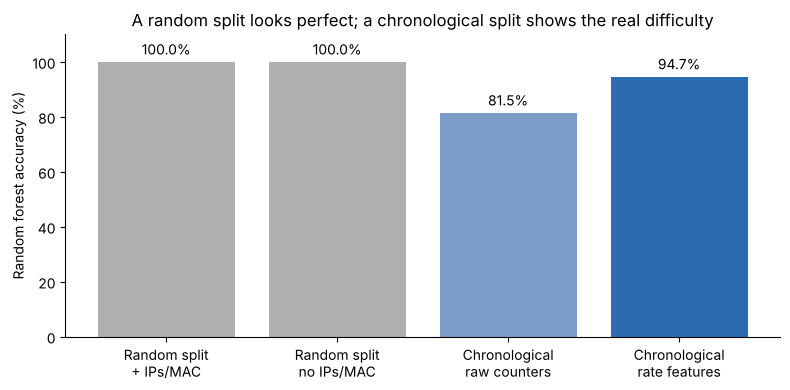

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
labels = [s[0] for s in settings]
colors = ["#b0b0b0", "#b0b0b0", "#7a9cc6", "#2b6cb0"]
bars = ax.bar(labels, leak_table["accuracy"] * 100, color=colors)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylim(0, 110); ax.set_ylabel("Random forest accuracy (%)")
ax.set_title("A random split looks perfect; a chronological split shows the real difficulty")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("images/evaluation_comparison.png", dpi=150); plt.show()

## 6. Train/test sets for the model comparison

All models use the **chronological split** and the **rate features**:

- **Training:** 20,000 records per class from the first 80% of each capture (80,000 total, balanced).
- **Test:** 8,000 records per class from the last 20% (32,000 total, balanced, never seen in training).
- The scaler is fit on training data only.

In [9]:
def balanced(indices, per_class):
    picks = [sample(indices[y_all[indices] == k], per_class) for k in range(len(CLASSES))]
    return np.concatenate(picks)

train_idx = balanced(chrono_train, 20_000)
test_idx = balanced(chrono_test, 8_000)

# signed log keeps large byte/packet rates from dominating
def prep(ix):
    x = df.loc[ix, rate_features].values.astype(np.float64)
    x = np.sign(x) * np.log1p(np.abs(x))
    return x
scaler = StandardScaler().fit(prep(train_idx))
X_train = scaler.transform(prep(train_idx)).astype(np.float32)
X_test = scaler.transform(prep(test_idx)).astype(np.float32)
y_train, y_test = y_all[train_idx], y_all[test_idx]
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (80000, 14)  Test: (32000, 14)


In [10]:
results, probs = {}, {}

def record(name, p_test):
    pred = p_test.argmax(1)
    probs[name] = p_test
    results[name] = {"accuracy": accuracy_score(y_test, pred), "macro_F1": f1_score(y_test, pred, average="macro")}
    print(f"{name}: accuracy {results[name]['accuracy']:.4f} | macro F1 {results[name]['macro_F1']:.4f}")

## 7. Baseline: random forest

In [11]:
rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED).fit(X_train, y_train)
record("Random forest", rf.predict_proba(X_test))

Random forest: accuracy 0.9459 | macro F1 0.9459


## 8. MLP (deep neural network)

In [12]:
def train_torch(model, X, y, epochs, lr=1e-3, batch=512):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    Xt, yt = torch.tensor(X), torch.tensor(y, dtype=torch.long)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xt)); total = 0
        for i in range(0, len(Xt), batch):
            b = perm[i:i + batch]
            opt.zero_grad(); loss = F.cross_entropy(model(Xt[b]), yt[b]); loss.backward(); opt.step()
            total += loss.item() * len(b)
        if ep % 3 == 0 or ep == epochs - 1:
            print(f"  epoch {ep + 1:2d}/{epochs}  loss {total / len(Xt):.4f}")
    return model

def predict_torch(model, X):
    model.eval()
    with torch.no_grad():
        return F.softmax(model(torch.tensor(X)), 1).numpy()

n_feat, n_cls = X_train.shape[1], len(CLASSES)
mlp = nn.Sequential(nn.Linear(n_feat, 128), nn.ReLU(), nn.Dropout(0.2),
                    nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2),
                    nn.Linear(64, n_cls))
train_torch(mlp, X_train, y_train, epochs=15)
record("MLP", predict_torch(mlp, X_test))

  epoch  1/15  loss 0.4686


  epoch  4/15  loss 0.2464


  epoch  7/15  loss 0.2268


  epoch 10/15  loss 0.2140


  epoch 13/15  loss 0.2035


  epoch 15/15  loss 0.1994
MLP: accuracy 0.9199 | macro F1 0.9197


## 9. Transformer (feature-token attention)

Each of the 14 features becomes a token (its value times a learned vector, plus a feature embedding). A 2-layer, 4-head Transformer encoder attends across features, and a `[CLS]` token makes the prediction.

In [13]:
class FeatureTransformer(nn.Module):
    def __init__(self, n_features, n_classes, d=32, heads=4, layers=2):
        super().__init__()
        self.value_proj = nn.Parameter(torch.randn(n_features, d) * 0.1)
        self.feature_emb = nn.Parameter(torch.randn(n_features, d) * 0.1)
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        layer = nn.TransformerEncoderLayer(d, heads, dim_feedforward=64, dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers)
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, n_classes))

    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.value_proj + self.feature_emb
        tokens = torch.cat([self.cls.expand(len(x), -1, -1), tokens], dim=1)
        return self.head(self.encoder(tokens)[:, 0])

transformer = FeatureTransformer(n_feat, n_cls)
train_torch(transformer, X_train, y_train, epochs=8)
record("Transformer", predict_torch(transformer, X_test))

  epoch  1/8  loss 0.3971


  epoch  4/8  loss 0.2222


  epoch  7/8  loss 0.2021


  epoch  8/8  loss 0.1986


Transformer: accuracy 0.9219 | macro F1 0.9219


## 10. GraphSAGE GNN

Each flow record is a node, connected to its 10 most similar records (k-nearest neighbours on the scaled features). GraphSAGE learns from each node's features plus its neighbours'. This is **transductive**: test nodes are in the graph, but their labels are hidden (`train_mask` / `test_mask`), and the loss uses training nodes only.

In [14]:
X_graph = np.vstack([X_train, X_test])
y_graph = np.concatenate([y_train, y_test])
nn_index = NearestNeighbors(n_neighbors=11).fit(X_graph)
_, neighbors = nn_index.kneighbors(X_graph)
src = np.repeat(np.arange(len(X_graph)), 10)
dst = neighbors[:, 1:].reshape(-1)
edge_index = torch.tensor(np.vstack([np.concatenate([src, dst]), np.concatenate([dst, src])]), dtype=torch.long)

graph = Data(x=torch.tensor(X_graph), edge_index=edge_index, y=torch.tensor(y_graph, dtype=torch.long))
graph.train_mask = torch.zeros(len(X_graph), dtype=torch.bool); graph.train_mask[:len(X_train)] = True
graph.test_mask = ~graph.train_mask
print(graph)

class GraphSAGE(nn.Module):
    def __init__(self, n_in, hidden, n_out):
        super().__init__()
        self.conv1, self.conv2 = SAGEConv(n_in, hidden), SAGEConv(hidden, hidden)
        self.out = nn.Linear(hidden, n_out)
    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, 0.2, self.training)
        x = F.relu(self.conv2(x, edge_index))
        return self.out(x)

gnn = GraphSAGE(n_feat, 64, n_cls)
opt = torch.optim.Adam(gnn.parameters(), lr=0.01)
for epoch in range(1, 151):
    gnn.train(); opt.zero_grad()
    loss = F.cross_entropy(gnn(graph.x, graph.edge_index)[graph.train_mask], graph.y[graph.train_mask])
    loss.backward(); opt.step()
    if epoch % 30 == 0:
        print(f"  epoch {epoch:3d}  loss {loss.item():.4f}")

gnn.eval()
with torch.no_grad():
    gnn_probs = F.softmax(gnn(graph.x, graph.edge_index), 1)[graph.test_mask].numpy()
record("GraphSAGE GNN", gnn_probs)

Data(x=[112000, 14], edge_index=[2, 2240000], y=[112000], train_mask=[112000], test_mask=[112000])


  epoch  30  loss 0.2538


  epoch  60  loss 0.2299


  epoch  90  loss 0.2118


  epoch 120  loss 0.2010


  epoch 150  loss 0.1922


GraphSAGE GNN: accuracy 0.9195 | macro F1 0.9192


## 11. Ensemble (average of the four models' probabilities)

In [15]:
record("Ensemble", np.mean([probs[m] for m in ["Random forest", "MLP", "Transformer", "GraphSAGE GNN"]], axis=0))

Ensemble: accuracy 0.9375 | macro F1 0.9374


## 12. Results

In [16]:
summary = pd.DataFrame(results).T.sort_values("accuracy", ascending=False).round(4)
summary

,accuracy,macro_F1
Random forest,0.9459,0.9459
Ensemble,0.9375,0.9374
Transformer,0.9219,0.9219
MLP,0.9199,0.9197
GraphSAGE GNN,0.9195,0.9192


In [17]:
best = summary.index[0]
print(f"Best model: {best}\n")
print(classification_report(y_test, probs[best].argmax(1), target_names=CLASSES, digits=3))

Best model: Random forest

              precision    recall  f1-score   support

      NORMAL      1.000     1.000     1.000      8000
       RECON      0.877     0.912     0.894      8000
    PHISHING      0.908     0.872     0.890      8000
     MALWARE      1.000     1.000     1.000      8000

    accuracy                          0.946     32000
   macro avg      0.946     0.946     0.946     32000
weighted avg      0.946     0.946     0.946     32000



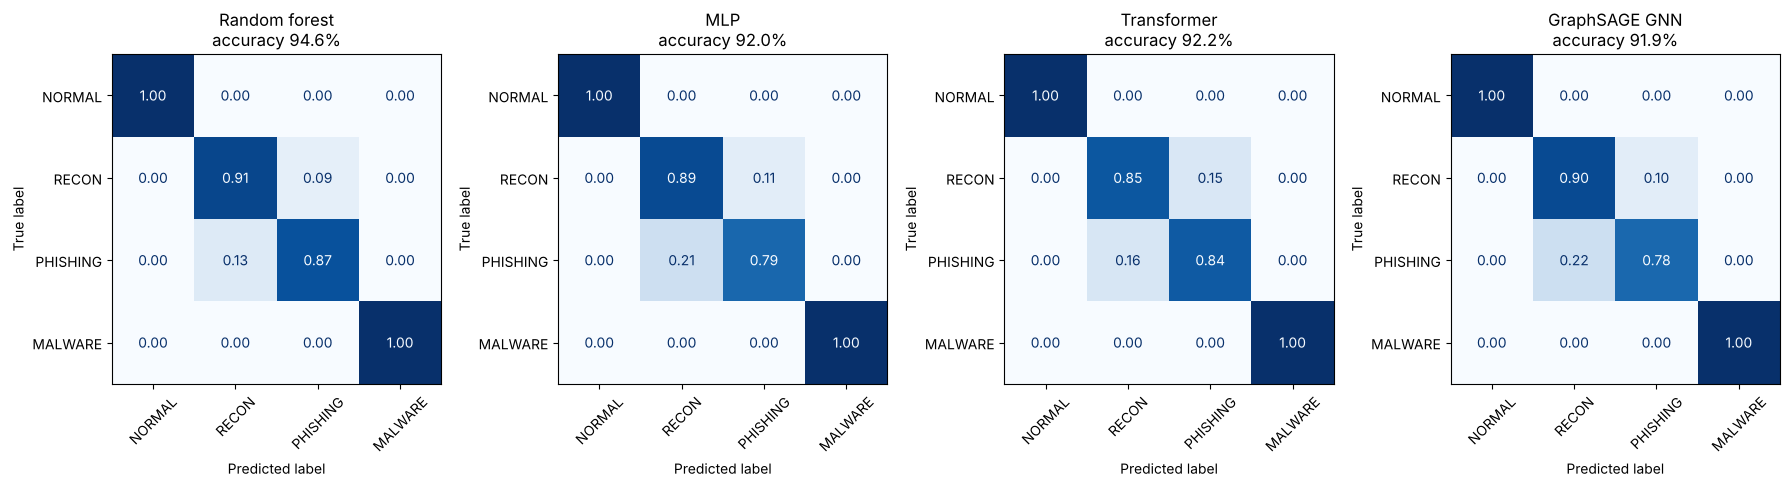

In [18]:
show = ["Random forest", "MLP", "Transformer", "GraphSAGE GNN"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, name in zip(axes, show):
    cm = confusion_matrix(y_test, probs[name].argmax(1), normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(f"{name}\naccuracy {results[name]['accuracy']:.1%}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig("images/confusion_matrices.png", dpi=150); plt.show()

## 13. Explainability with GNNExplainer

GNNExplainer finds the small set of features and neighbouring edges that most influenced one prediction, so an analyst can see *why* a flow was flagged instead of trusting a black box. Below, it explains test-node predictions for each attack class, and the feature importances are averaged.

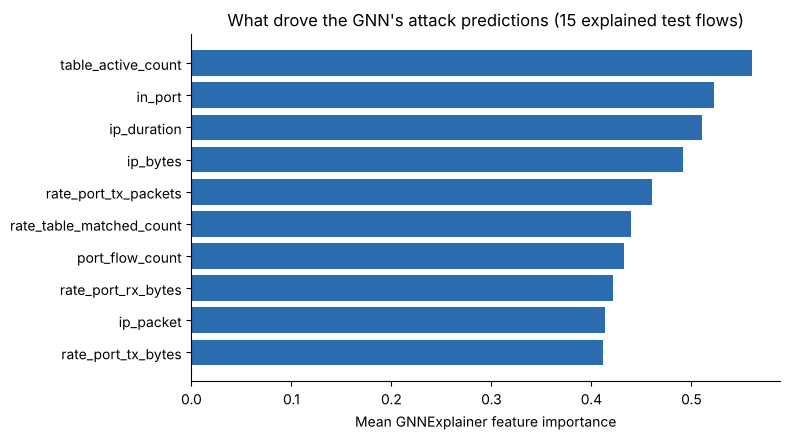

In [19]:
from torch_geometric.explain import Explainer, GNNExplainer
from torch_geometric.utils import k_hop_subgraph

explainer = Explainer(
    model=gnn, algorithm=GNNExplainer(epochs=100),
    explanation_type="model", node_mask_type="attributes", edge_mask_type="object",
    model_config=dict(mode="multiclass_classification", task_level="node", return_type="raw"),
)

test_nodes = np.where(graph.test_mask.numpy())[0]
pred_all = gnn_probs.argmax(1)
importance = np.zeros(n_feat)
explained = 0
for k in range(1, len(CLASSES)):                     # the three attack classes
    correct = test_nodes[(y_test == k) & (pred_all == k)]
    for node in rng.choice(correct, 5, replace=False):
        # explain on the node's 2-hop neighbourhood (the only part a 2-layer GNN can see)
        subset, sub_edges, center, _ = k_hop_subgraph(int(node), 2, graph.edge_index, relabel_nodes=True)
        exp = explainer(graph.x[subset], sub_edges, index=int(center))
        importance += exp.node_mask[int(center)].abs().numpy()
        explained += 1
importance /= explained

order = np.argsort(importance)[::-1][:10]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh([rate_features[i] for i in order][::-1], importance[order][::-1], color="#2b6cb0")
ax.set_xlabel("Mean GNNExplainer feature importance")
ax.set_title(f"What drove the GNN's attack predictions ({explained} explained test flows)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("images/gnnexplainer_features.png", dpi=150); plt.show()

## 14. Takeaways

- **Evaluation matters more than model choice.** A random split gives ~100% for any model because neighbouring time-series rows leak. The chronological split is the honest benchmark.
- **Feature engineering beat architecture.** Turning cumulative counters into per-interval rates lifted the random forest from 81.5% to 94.7% under the honest split (section 5), a bigger gain than any model change.
- **Classical ML still won on this tabular data.** On the same 32,000 unseen, balanced test flows: random forest 94.6%, ensemble 93.8%, Transformer 92.2%, MLP 92.0%, GraphSAGE GNN 91.9%.
- **Where the errors are:** Normal and Malware (DDoS) are separated perfectly. Every model's mistakes come from mixing up Recon and Phishing, which both come from the same attacker host.
- **Limitations:** the data comes from one lab testbed, `in_port` and `table_active_count` may still carry testbed-specific signal, and the GNN is transductive (test nodes sit in the graph with hidden labels).
- **Next steps:** test on traffic from a different network, make the GNN inductive, and run the model inside an SDN controller (Ryu/ONOS) for live detection.